**1. Método de Relajación**

Dada la ecuación $x = 1-e^{-cx}$ que es muy popular, hacer lo siguiente:

a) Encontrar $x$ para $c=2$ con una exactitud $\epsilon_n$ de al menos $10^{-6}$

Tal tarea no parece complicada porque prácticamente ya lo hemos hecho durante las sesiones. Aunque quizá tenga que ajustar algunas cosas, todo está bajo control.

Primero, considerar que el error vendrá dado por:

$\epsilon_{n} = \frac{x_{n-1}-x_n}{1-1/f'(x^*)}$

La derivada necesita cumplir con: $|f'(x^*)| < 1$.

En este caso: $f'(x) = ce^{-cx}$

In [85]:
import numpy as np
import matplotlib.pyplot as plt #bibliotecas necesarias

##########

c=2 #valor de c

def f(x):
    return 1-np.exp(-c*x) #la función, de una vez le pongo dos argumentos

def idf(x):
    return (1/c)*np.exp(c*x) #inversa de la derivada

def exc(x1,x,idf):
    return -(x1-x)/(1-idf(x)) #error

In [86]:
xn = 1 #condición inicial
e = 1

#for i in range(15):

while e > 1e-6: #exactitud pedida.
    x1 = xn
    xn = f(xn)
    e = exc(x1,xn,idf)

print(xn)
print("Exactitud =", e)

0.7968126311118457
Exactitud = 5.010920207189714e-07


b) Hacer lo mismo para todas las c entre 0 y 3 con un paso de 0.01 (eso lo puedo hacer con arange).

Pues ya

In [33]:
cs = np.arange(0.01,3,0.01) #todas las c de 0 a 3 en pasos de 0.01. No pongo el cero para no dividir por cero
xns = [] #aquí guardaré las xs que vayan saliendo para cada c
E = [] #los errores, por si hiciera falta

for c in cs:
    xn = 1 #condición inicial
    e = 1
    while e > 1e-6: #exactitud pedida.
        x1 = xn
        xn = f(xn)
        e = exc(x1,xn,idf)
    xns.append(xn)
    E.append(e)  

Text(0, 0.5, 'Valor de x')

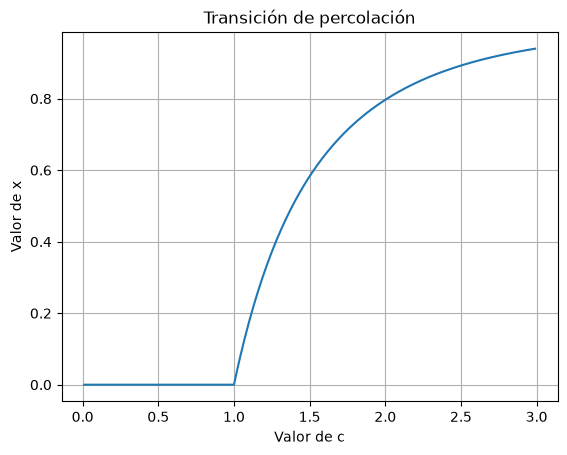

In [34]:
import matplotlib.pyplot as plt

plt.plot(cs,xns)
plt.title("Transición de percolación")
plt.grid()
plt.xlabel("Valor de c")
plt.ylabel("Valor de x")

**2. Glucólisis**

a y b) Parto de las ecuaciones:

$-x+ay+x^2y = 0$ y $b-ay-x^2y=0$.

Si sumo $x$ a ambos lados de la primera se obtiene:

$ay+x^2y = x$

Factorizando y:

$x = y(a+x^2)$.

De manera similar, puedo multiplicar por $-1$ a la primera ecuación y luego sumar b a ambos lados de la ecuación, obteniendo:

$ay+x^2y = b$

Factorizando y:

$y(a+x^2) = b$

Por último: 

$y = \frac{b}{a+x^2}$

De estas últimas dos ecuaciones y de la ecuación para x se concluye:

$x = b$ y $y=\frac{b}{a+b^2}$

Ahora la parte numérica. Para $a=1,b=2$ debería de obtener $x=2, y = 0.4$

In [1]:
def f1(x):
    return y*(a+x**2) #defino la primer ecuación, voy a tener que dar un valor de y.

def f2(x):
    return b/(a+x**2) #defino la segunda ecuación

In [24]:
N = 2 #iteraciones

a=1
b=2 #valores de a y b

x = 0.67 #condición inicial.
y = -0.67 #condición inicial para y

for i in range(N): #primero calculo x
    x = f1(x)
    for i in range(N): #luego calculo y para esa misma x
        y = f2(x)
        print("x:",x,"y:",y)

        
print("x final:",x)
print("y final:",y)

x: -0.9707630000000002 y: 1.029664212994001
x: -0.9707630000000002 y: 1.029664212994001
x: 2.0 y: 0.4
x: 2.0 y: 0.4
x final: 2.0
y final: 0.4


Ayuda, sí salió. De todas formas, para c) usaré la ecuación $x = \sqrt{x/y - a}$ en su lugar, no veo necesidad de cambiar la ecuación para $y$ aun.

In [12]:
def f3(x):
    return np.sqrt(x/y - a)

In [18]:
N = 5 #iteraciones

a=1
b=2 #valores de a y b

x = 3 #condición inicial.
y = 1 #condición inicial para y

for i in range(N):
    x = f3(x)
    print("x=",x)
    for i in range(N): #luego calculo y
        y = f2(x)
    
print("x=",x)
print("y=",y)

x= 1.4142135623730951
x= 1.0589241443841213
x= 0.35093968838571515
x= nan
x= nan
x= nan
y= nan


/tmp/ipykernel_28851/752423167.py:2: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(x/y - a)


Con este no sale, supongo que es porque en la raíz termina apareciendo un argumento negativo.

El método que mostró nuestro compañero en clase fue bastante más directo, y además le permitió poner un límite al número de iteraciones en función del error. Creo que no sería imposible implementar lo mismo al método que usé yo, pero dado que no viene como indicación en la tarea, no lo haré porque soy un alumno que le encanta ser autodidacta.

Eso sí, su método me parece más conveniente para funciones generales de dos variables y además más eficiente (yo tengo dos ciclos if concatenados, si salió bien es porque las funciones son sencillas y necesité pocas iteraciones).

**3. Constante de desplazamiento de Wien**

La derivación puede esperar, primero hay que programar el método de búsqueda binaria.

Tengo que elegir un intervalo donde mi función $g(x) = f(x)-x$ cambie de signo de un lado al otro, lo que me indicará que hay una solución ahí en medio. Para buscar la solución hay que reducir el tamaño de ese intervalo hasta que solo quede la solución; creo recordar que en clase se sugirió dividir el intervalo en 2 en cada intento, sin embargo, para un intervalo en el que la solución se encuentre muy cerca de los extremos, hacer eso podría sacarla del nuevo intervalo muy rápido. Arreglar este problema es tan sencillo como tomar como nuevo intervalo al complemento (lo que sacamos) y repetir. El reto es programar eso.

Dado un intervalo $[a,b]$ primero debo verificar el signo del producto $f(a)f(b)$. Si es positivo, ahí en medio no hay ningún cero, hay que cambiar el intervalo, quizá puedo terminar el programa ahí o simplemente extender el intervalo hasta que encontrar un cambio de signo.

Problemas para después, supongamos que encontré el cambio de signo. Procedo a dividir el intervalo en dos por la izquierda (es decir, me quedo con la parte derecha), no importa la manera en la que se hace (creo), solo añadirá o quitará más pasos al algoritmo si tenemos buena o mala suerte. Parto desde el punto a y selecciono un nuevo intervalo justo a la mitad, i. e. $[a, \frac{a+b}{2}]$ y vuelvo a verificar el signo de $f(a)f(\frac{a+b}{2})$, si el signo es positivo quiere decir que el cero está en la otra mitad, en $[\frac{a+b}{2},b]$ así que procedo a dividirlo en 2 y repetir; si el signo fuera negativo, divido en 2 y repito.

Eso suena bien, pero al final tendré que elegir un punto en medio de ese intervalo. Quizá, tras una cierta cantidad de iteraciones, puedo guardar el intervalo final y ver qué hacer con él, intentaré llegar hasta ese punto primero.

In [14]:
import numpy as np

In [77]:
def f(x):
    return 1-np.exp(-2*x)-x #la función del primer ejercicio, para tener una referencia.

In [78]:
a,b = 0.1,1 #aprovecho que conozco la solución para elegir un intervalo conveniente desde el inicio.

In [79]:
a1,b1=a,b #los extremos que iré cambiando
a2,b2 =a,b #extremos de la iteración anterior (por si hiciera falta cambiar de intervalo)

for i in range(100):

    if f(a1)*f(b1) < 0: #si el cero está en mi intervalo, hago lo siguiente:
        b2 = b1 #guardo mi extremo izquierdo actual
        b1 = (a1+b1)/2 #cambio mi extremo izquierdo por la mitad
    else:  #si el cero no está en esta mitad, habrá que elegir la otra
        a1 = b1 #mi extremo derecho lo cambio por mi extremo izquierdo actual
        b1 = b2 #mi extremo izquierdo actual lo muevo al anterior

        
#este código solo funciona si el primer intervalo dado ya tiene un cero en medio.
#para arreglarlo, quizá baste con agregar un primer if que verifique que el intervalo inicial es adecuado antes de comenzar el algoritmo.

In [87]:
a1 #resultado final

0.7968121300200209

In [84]:
a1-b1

0.0

Al final de todas esas iteraciones, el intervalo sí que es pequeño y la diferencia entre los extremos es más bien minúscula. Supongo que se podría elegir cualquiera de los dos, pero hay que estar atentos del error, eso apenas lo veremos en la clase de hoy.

In [88]:
xn #resultado del método de relajación

np.float64(0.7968126311118457)

In [90]:
xn-a1 #diferencia entre los resultados

np.float64(5.01091824811617e-07)

Juntaré todo e intentaré añadir un mensaje en caso de que el primer intervalo no contenga un cero. No sé qué se podría hacer si hubiese más de un cero, como es el caso de este ejemplo.

In [7]:
import numpy as np

def f(x):
    return 1-np.exp(-2*x)-x

a,b = 0.1,1 #intervalo

if f(a)*f(b) < 0: #si el intervalo es adecuado, inicio el algoritmo.

    a1,b1=a,b #los extremos que iré cambiando
    a2,b2 =a,b #extremos de la iteración anterior (por si hiciera falta cambiar de intervalo)
    
    while a1-b1 != 0: #Dado que no hemos visto cómo calcular el error de este método, usaré esto como referencia.
    
        if f(a1)*f(b1) < 0: #si el cero está en mi intervalo, hago lo siguiente:
            b2 = b1 #guardo mi extremo izquierdo actual
            b1 = (a1+b1)/2 #cambio mi extremo izquierdo por la mitad
        else:  #si el cero no está en esta mitad, habrá que elegir la otra
            a1 = b1 #mi extremo derecho lo cambio por mi extremo izquierdo actual
            b1 = b2 #mi extremo izquierdo actual lo muevo al anterior

else: #si el intervalo dado no contiene un cero, no iniciar nada.
    print("Elegir otro intervalo, por favor.")

Ahora sí. El ejercicio.

**Radiación de Planck:** $I(\lambda) = \frac{2 \pi h c^2 \lambda^{-5}}{e^{hc/\lambda k_B T}-1}$.

Si derivamos esa función se obtiene:

$$I'(\lambda) = 2\pi h c^2 \left[ -5 \lambda^{-6}(e^{\frac{hc}{k_B T}\lambda^{-1}}-1)^{-1} - \lambda^{-5}(e^{\frac{hc}{k_B T}\lambda^{-1}}-1)^{-2} \frac{hc}{k_B T} e^{\frac{hc}{k_B T}\lambda^{-1}}(-\lambda^{-2})  \right]$$

Para obtener el valor de la longitud de onda que minimiza la intensidad, se iguala esa derivada a cero, obteniendo:

$$-5 \lambda^{-6}(e^{\frac{hc}{k_B T}\lambda^{-1}}-1)^{-1} + \lambda^{-7}(e^{\frac{hc}{k_B T}\lambda^{-1}}-1)^{-2} \frac{hc}{k_B T} e^{\frac{hc}{k_B T}\lambda^{-1}} = 0$$

Multiplicamos por $(e^{\frac{hc}{k_B T}\lambda^{-1}}-1)^{2}$:

$$-5 \lambda^{-6}(e^{\frac{hc}{k_B T}\lambda^{-1}}-1) + \lambda^{-7} \frac{hc}{k_B T} e^{\frac{hc}{k_B T}\lambda^{-1}} = 0$$

Se distribuyen los paréntesis y se multiplica por $e^{-\frac{hc}{\lambda k_B T}\lambda^6}$ para finalmente obtener:

$$5e^{-\frac{hc}{\lambda k_B T}} + \frac{hc}{\lambda k_B T} - 5 = 0$$

Lo demás se deja al lector.

b) Resolver: $5e^{-x} +x -5 = 0$. Dado que no puedo seleccionar el error porque no lo vimos en clase, reciclaré el código de arriba.

In [21]:
import numpy as np

def f(x):
    return 5*np.exp(-x)+x-5

a,b = 3,5 #intervalo

if f(a)*f(b) < 0: #si el intervalo es adecuado, inicio el algoritmo.

    a1,b1=a,b #los extremos que iré cambiando
    a2,b2 =a,b #extremos de la iteración anterior (por si hiciera falta cambiar de intervalo)
                #solo hizo falta cambiar b2
    
    while a1-b1 != 0: #Dado que no hemos visto cómo calcular el error de este método, usaré esto como referencia.
    
        if f(a1)*f(b1) < 0: #si el cero está en mi intervalo, hago lo siguiente:
            b2 = b1 #guardo mi extremo izquierdo actual
            b1 = (a1+b1)/2 #cambio mi extremo izquierdo por la mitad
        else:  #si el cero no está en esta mitad, habrá que elegir la otra
            a1 = b1 #mi extremo derecho lo cambio por mi extremo izquierdo actual
            b1 = b2 #mi extremo izquierdo actual lo muevo al anterior

else: #si el intervalo dado no contiene un cero, no iniciar nada.
    print("Elegir otro intervalo, por favor.")

In [20]:
b1 #esto es cero, pero por la definición de b, no puedo tomar este valor. De la gráfica sé que existe otro cero, así que cambio mi intervalo

2.220446049250313e-16

In [22]:
a1

4.965114231744277

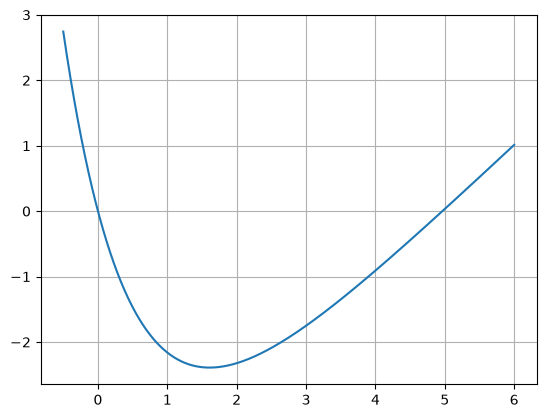

In [116]:
def f(x):
    return 5*np.exp(-x)+x-5
    
X = np.linspace(-0.5,6,1000)

plt.plot(X,f(X))
plt.grid()

Luego, $b = \frac{hc}{k_B x}$. Luego, $\lambda = b/T \rightarrow T = b/\lambda$

In [126]:
h = 6.626*1e-34 #constante de planck
c = 3*1e+8 #velocidad de la luz en el vacío
kB = 1.38*1e-23 #constante de boltzman
x = a1 #el valor que obtuve antes

b = (h*c)/(kB*x)

In [127]:
b #constante de wien

0.0029011110628620156

In [128]:
lmbd = 502*1e-9 #longitud de onda que me dan
T = b/lmbd
print("La temperatura aproximada en la superficie solar es:", T, "K")

La temperatura aproximada en la superficie solar es: 5779.105702912381 K


**4) El punto de Lagrange**

a) No probaré nada chistoso, yuju. La ecuación a resolver es la siguiente:

$$\frac{GM}{r^2} - \frac{Gm}{(R-r)^2} = \omega^2 r$$

Que se traduce a resolver $f(r) = 0$ para:

$$f(r) = \frac{GM}{r^2} - \frac{Gm}{(R-r)^2} - \omega^2 r$$

Ya programamos el método de Newton-Rhapson durante la clase, así que primero lo copiaré aquí. No sin antes graficar eso para elegir un valor inicial adecuado para $r$.

In [136]:
def f(r):
    G = 6.674*1e-11 #constante gravitacional
    M = 5.974*1e+24 #masa de la Tierra
    m = 7.349*1e+22 #masa de la Luna
    om = 2.662*1e-6 #velocidad angular
    R = 3.844*1e+8 #distancia de la Tierra a la Luna
    return (G*M)/(r**2)-(G*m)/(R-r)**2 - (om**2)*r

In [138]:

import numpy as np

def df(r):
    G = 6.674*1e-11 #constante gravitacional
    M = 5.974*1e+24 #masa de la Tierra
    m = 7.349*1e+22 #masa de la Luna
    om = 2.662*1e-6 #velocidad angular
    R = 3.844*1e+8 #distancia de la Tierra a la Luna
    return -2*(G*M)/(r**3) - 2*(G*m)/(R-r)**3 -om**2

r = 1e+8 #punto de inicio. Tomé este por ser comparable a la distancia a la luna, pero menor
error = 1

while error > 1e-6:

    r1 = r #término anterior
    
    r = r - f(r)/df(r) #fórmula

    error = r1-r #error
    
print("El punto de Lagrange L_1 se encuentra a una distancia aproximada de ",r,"m desde el centro de la Tierra")

El punto de Lagrange L_1 se encuentra a una distancia aproximada de  148577629.0703329 m desde el centro de la Tierra
